# Parts and Suppliers
## Procurement costs, supplier performance and purchasing opportunities

**Collaborative academic project · TOTI · Class 59 · Group 05**  
**Participants:** Jeff-Mathieu Saint-Amour; Samuel Owens Fumero Fuentes; Gabriel Enrique Marcano López.  
**Portfolio:** Jeff-Mathieu Saint-Amour · Data Analyst · Civil Engineer · PhD Student in Production Engineering.  
**Tools:** Python, Pandas, NumPy, SQLite, Matplotlib and Power BI.

This notebook documents the analytical workflow and its business interpretation.

## 1. Data source and analytical scope

This project uses a **synthetic academic procurement dataset** comprising **100 parts across eight categories, 10 suppliers, 394 supplier quotes and 2,500 purchase orders** covering **January 2025 through September 2026**. The data are organized into five related tables: parts, suppliers, quotations, purchase orders and calendar dates.

This notebook analyzes procurement costs, supplier performance and purchasing opportunities through an integrated **Python–SQL–Power BI workflow**. It examines spending concentration, purchasing trends, delivery reliability, product quality, quote dispersion and supplier coverage to support procurement prioritization and business interpretation.

### Analytical methodology

The methodology follows six connected stages:

1. **Data loading and preparation:** Pandas imports the structured tables, assigns appropriate numeric and date types, and prepares the fields required for analysis.

2. **Data quality validation:** Checks assess missing values, duplicate identifiers, relationships between tables, valid prices and quantities, delivery-date consistency and the agreement between purchase amounts and quantity multiplied by unit price.

3. **Relational analysis with SQL:** The tables are stored in SQLite. Queries calculate purchasing totals, monthly spending, category and supplier contributions, delivery delays, defect rates and supplier coverage.

4. **Indicator development with Pandas and NumPy:** Calculations evaluate relative quote gaps, estimate potential savings at part level and classify parts into four purchasing priority groups using spending and quote-gap thresholds. A supplementary supplier score combines cost, punctuality, quality and coverage indicators through min-max normalization and explicit weights.

5. **Visualization and interpretation:** Charts and analytical summaries highlight spending patterns, supplier performance and purchasing opportunities. SQL and Pandas results are compared to verify consistency across the analytical workflow.

6. **Reporting and analytical exports:** Results are exported as structured tables to support further inspection and Power BI reporting. The report organizes the findings into four perspectives: Executive Overview, Supplier Performance, Parts Analysis, and Recommendations and Conclusions.

### Interpretation and data access

Potential savings compare purchasing expenditure with a scenario based on the lowest available quote for each part. These estimates identify opportunities for assessment rather than realized financial gains. Their interpretation requires consideration of delivery performance, quality, supplier capacity, contractual conditions and other purchasing constraints.

The dataset is intended for academic demonstration. Record-level inputs and the editable Power BI file remain outside the public portfolio; access may be considered upon request, subject to the project team's agreement.

## 2. Environment and source configuration

Standard analytical libraries support reproducible tabular processing and relational queries. Explicit source and output paths separate approved inputs from generated analytical artifacts.

In [ ]:
import os
import sys
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path(os.environ.get("PARTS_SUPPLIERS_DATA_DIR", "/content/parts_suppliers_inputs"))
OUTPUT_DIR = Path(os.environ.get("PARTS_SUPPLIERS_OUTPUT_DIR", "/content/parts_suppliers_outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
print({"Python": sys.version.split()[0], "Pandas": pd.__version__, "NumPy": np.__version__, "Matplotlib": matplotlib.__version__, "SQLite": sqlite3.sqlite_version})

{'Python': '3.12.14', 'Pandas': '2.2.3', 'NumPy': '2.3.5', 'Matplotlib': '3.10.8', 'SQLite': '3.53.1'}


In [ ]:
input_files = {
    "pecas": "dim_pecas.csv", "fornecedores": "dim_fornecedores.csv",
    "ofertas": "fato_ofertas.csv", "compras": "fato_compras.csv",
    "calendario": "dim_calendario.csv",
}
missing_files = [filename for filename in input_files.values() if not (DATA_DIR / filename).is_file()]
if missing_files:
    raise FileNotFoundError("Approved prepared inputs are required: " + ", ".join(missing_files))
tables = {name: pd.read_csv(DATA_DIR / filename) for name, filename in input_files.items()}
pecas, fornecedores, ofertas, compras, calendario = (tables[name] for name in input_files)
for column in ["preco_unitario", "valor_total", "quantidade", "dias_atraso", "unidades_defeituosas"]:
    compras[column] = pd.to_numeric(compras[column], errors="raise")
ofertas["preco_ofertado"] = pd.to_numeric(ofertas["preco_ofertado"], errors="raise")
for column in ["data_pedido", "data_prevista", "data_entrega"]:
    compras[column] = pd.to_datetime(compras[column], errors="raise")
calendario["data"] = pd.to_datetime(calendario["data"], errors="raise")
compras["ano_mes"] = compras["data_pedido"].dt.strftime("%Y-%m")
display(pd.DataFrame([{"Table": name, "Rows": len(frame), "Columns": len(frame.columns)} for name, frame in tables.items()]))

,Table,Rows,Columns
0,pecas,100,5
1,fornecedores,10,4
2,ofertas,394,5
3,compras,2500,16
4,calendario,638,8


## 3. Data integrity

Duplicate identifiers, missing fields, invalid numeric values, orphan keys and inconsistent dates can distort aggregated indicators. These checks also reconcile order amounts to quantity multiplied by unit price. Failure stops the workflow before analysis.

In [ ]:
checks = {
    "Duplicate part keys": int(pecas.codigo_peca.duplicated().sum()),
    "Duplicate supplier keys": int(fornecedores.codigo_fornecedor.duplicated().sum()),
    "Duplicate order IDs": int(compras.id_pedido.duplicated().sum()),
    "Duplicate quote pairs": int(ofertas.duplicated(["codigo_peca", "codigo_fornecedor"]).sum()),
    "Duplicate calendar dates": int(calendario.data.duplicated().sum()),
    "Missing values": int(sum(frame.isna().sum().sum() for frame in tables.values())),
    "Invalid purchase prices": int((compras.preco_unitario <= 0).sum()),
    "Invalid quote prices": int((ofertas.preco_ofertado <= 0).sum()),
    "Invalid quantities": int(((compras.quantidade <= 0) | (compras.quantidade % 1 != 0)).sum()),
    "Invalid defect counts": int(((compras.unidades_defeituosas < 0) | (compras.unidades_defeituosas > compras.quantidade)).sum()),
    "Invalid delay values": int((compras.dias_atraso < 0).sum()),
    "Orphan purchase part keys": int((~compras.codigo_peca.isin(pecas.codigo_peca)).sum()),
    "Orphan purchase supplier keys": int((~compras.codigo_fornecedor.isin(fornecedores.codigo_fornecedor)).sum()),
    "Orphan quote part keys": int((~ofertas.codigo_peca.isin(pecas.codigo_peca)).sum()),
    "Orphan quote supplier keys": int((~ofertas.codigo_fornecedor.isin(fornecedores.codigo_fornecedor)).sum()),
    "Parts without quotes": int((~pecas.codigo_peca.isin(ofertas.codigo_peca)).sum()),
    "Orders outside calendar": int((~compras.data_pedido.isin(calendario.data)).sum()),
    "Delivery before order": int((compras.data_entrega < compras.data_pedido).sum()),
    "Inconsistent delay days": int((compras.dias_atraso != (compras.data_entrega - compras.data_prevista).dt.days.clip(lower=0)).sum()),
    "Inconsistent line amounts": int((abs(compras.valor_total - compras.quantidade * compras.preco_unitario) > 0.011).sum()),
}
validation = pd.DataFrame(checks.items(), columns=["Check", "Issues"])
display(validation)
if validation.Issues.any():
    raise ValueError("Data integrity validation failed.")
print(f"All {len(checks)} integrity checks passed.")

All 20 integrity checks passed.


,Check,Issues
0,Duplicate part keys,0
1,Duplicate supplier keys,0
2,Duplicate order IDs,0
3,Duplicate quote pairs,0
4,Duplicate calendar dates,0
5,Missing values,0
6,Invalid purchase prices,0
7,Invalid quote prices,0
8,Invalid quantities,0
9,Invalid defect counts,0


## 4. Relational analytical layer

The SQLite database stores the four business tables at their original grain. Identifier integrity is verified explicitly above; `to_sql` does not create foreign-key constraints. ISO date strings preserve cross-tool compatibility.

In [ ]:
conn = sqlite3.connect(OUTPUT_DIR / "parts_suppliers.db")
for name in ["pecas", "fornecedores", "ofertas", "compras"]:
    frame = tables[name].copy()
    if name == "compras":
        for column in ["data_pedido", "data_prevista", "data_entrega"]:
            frame[column] = frame[column].dt.strftime("%Y-%m-%d")
    frame.to_sql(name, conn, if_exists="replace", index=False)
print("Four analytical tables loaded into SQLite.")

Four analytical tables loaded into SQLite.


## 5. Purchasing overview

Spend, quantity and order count establish the scale of the retained reporting snapshot.

In [ ]:
q1 = pd.read_sql_query("""
SELECT
    ROUND(SUM(valor_total), 2) AS gasto_total,
    SUM(quantidade) AS unidades_compradas,
    COUNT(DISTINCT id_pedido) AS total_pedidos,
    ROUND(AVG(valor_total), 2) AS ticket_medio
FROM compras;
""", conn)
display(q1)

,gasto_total,unidades_compradas,total_pedidos,ticket_medio
0,"133,493,473.9000",636430,2500,"53,397.3900"


## 6. Monthly purchasing patterns

Order-month aggregation separates time variation from full-period totals.

In [ ]:
q2 = pd.read_sql_query("""
SELECT
    ano_mes,
    ROUND(SUM(valor_total), 2) AS gasto_mensal,
    SUM(quantidade) AS quantidade_mensal,
    COUNT(*) AS pedidos
FROM compras
GROUP BY ano_mes
ORDER BY ano_mes;
""", conn)
display(q2)

,ano_mes,gasto_mensal,quantidade_mensal,pedidos
0,2025-01,"5,976,869.9400",28742,118
1,2025-02,"6,240,783.5000",26780,105
2,2025-03,"5,852,778.1100",30434,123
3,2025-04,"6,456,635.1700",30960,125
4,2025-05,"7,034,896.0000",35586,130
5,2025-06,"7,075,093.5700",31090,123
6,2025-07,"5,725,411.3700",28029,117
7,2025-08,"6,189,156.8500",32841,122
8,2025-09,"5,737,260.2500",26857,111
9,2025-10,"8,146,876.7900",36838,140


## 7. Spending by category

Shared part keys connect transaction amounts to category-level concentration.

In [ ]:
q3 = pd.read_sql_query("""
SELECT
    p.categoria,
    ROUND(SUM(c.valor_total), 2) AS gasto_total,
    SUM(c.quantidade) AS unidades,
    ROUND(100.0 * SUM(c.valor_total) / (SELECT SUM(valor_total) FROM compras), 2) AS participacao_gasto_pct
FROM compras c
JOIN pecas p ON p.codigo_peca = c.codigo_peca
GROUP BY p.categoria
ORDER BY gasto_total DESC;
""", conn)
display(q3)

,categoria,gasto_total,unidades,participacao_gasto_pct
0,Fastening,"27,049,354.4900",103439,20.2600
1,Safety,"24,169,817.8700",117641,18.1100
2,Tooling,"18,168,507.2200",76236,13.6100
3,Electrical,"17,485,948.4200",98289,13.1000
4,Structural,"16,433,041.8200",91816,12.3100
5,Transmission,"12,866,345.8300",44157,9.6400
6,Hydraulic,"12,392,331.0500",77039,9.2800
7,Pneumatic,"4,928,127.2000",27813,3.6900


## 8. Supplier performance

Supplier indicators combine spending, order volume, purchased-part coverage, late deliveries and quantity-weighted defect rates.

In [ ]:
q4 = pd.read_sql_query("""
SELECT
    f.codigo_fornecedor,
    f.nome_fornecedor,
    f.estado,
    ROUND(SUM(c.valor_total), 2) AS gasto_total,
    COUNT(*) AS total_pedidos,
    COUNT(DISTINCT c.codigo_peca) AS pecas_fornecidas,
    ROUND(100.0 * SUM(CASE WHEN c.dias_atraso > 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS taxa_atraso_pct,
    ROUND(AVG(c.dias_atraso), 2) AS atraso_medio_dias,
    ROUND(100.0 * SUM(c.unidades_defeituosas) / SUM(c.quantidade), 2) AS taxa_defeito_pct
FROM compras c
JOIN fornecedores f ON f.codigo_fornecedor = c.codigo_fornecedor
GROUP BY f.codigo_fornecedor, f.nome_fornecedor, f.estado
ORDER BY gasto_total DESC;
""", conn)
display(q4)

,codigo_fornecedor,nome_fornecedor,estado,gasto_total,total_pedidos,pecas_fornecidas,taxa_atraso_pct,atraso_medio_dias,taxa_defeito_pct
0,F02,Boreal Supplies,RS,"17,329,959.4700",283,34,48.7600,1.3600,1.4900
1,F07,Global Mechanics,GO,"16,889,621.1700",277,35,48.7400,1.4700,1.7800
2,F10,Jupiter Supply,ES,"15,449,481.8400",258,38,45.7400,1.1300,0.9400
3,F04,Delta Parts,SC,"15,395,901.1300",368,46,51.9000,2.1400,2.8600
4,F09,Ion Systems,PE,"15,149,853.8200",295,40,51.1900,1.5700,2.2700
5,F05,Strong Axis,MG,"12,702,178.6100",211,36,46.4500,1.2200,1.2000
6,F06,Phoenix Materials,RJ,"12,681,631.1300",273,34,48.3500,2.0400,3.2000
7,F01,Atlas Components,SP,"10,740,285.4400",197,31,39.5900,0.8400,0.8200
8,F08,Horizon Parts,BA,"10,515,656.0100",211,34,39.8100,1.0700,1.0400
9,F03,Conecta Industrial,PR,"6,638,905.2800",127,32,47.2400,1.6700,1.0300


## 9. Parts with the highest spend

Part-level spending identifies items with the largest financial exposure.

In [ ]:
q5 = pd.read_sql_query("""
SELECT
    p.codigo_peca,
    p.nome_peca,
    p.categoria,
    p.criticidade,
    ROUND(SUM(c.valor_total), 2) AS gasto_total,
    SUM(c.quantidade) AS quantidade,
    ROUND(AVG(c.preco_unitario), 2) AS preco_medio
FROM compras c
JOIN pecas p ON p.codigo_peca = c.codigo_peca
GROUP BY p.codigo_peca, p.nome_peca, p.categoria, p.criticidade
ORDER BY gasto_total DESC
LIMIT 15;
""", conn)
display(q5)

,codigo_peca,nome_peca,categoria,criticidade,gasto_total,quantidade,preco_medio
0,P001,Industrial Bolt 001,Fastening,Medium,"9,449,368.2500",28452,332.8400
1,P002,Industrial Nut 002,Fastening,Medium,"8,086,557.0000",20572,395.7800
2,P093,Industrial Lock 093,Safety,Medium,"6,225,789.7900",18571,332.2000
3,P095,Industrial Signal Light 095,Safety,Low,"4,895,078.8700",14195,344.7500
4,P029,Industrial Lock 029,Safety,Medium,"4,257,434.3000",21906,200.1400
5,P025,Industrial Drill Bit 025,Tooling,Low,"4,194,272.5500",14481,285.4900
6,P075,Industrial Fuse 075,Electrical,Low,"3,664,952.7000",17023,217.4900
7,P091,Industrial Disc 091,Tooling,High,"3,566,403.1000",8156,441.6700
8,P074,Industrial Relay 074,Electrical,Medium,"3,259,604.5200",23325,141.3500
9,P033,Industrial Bolt 033,Fastening,Medium,"3,089,158.9900",11761,271.2600


## 10. Quote dispersion

Relative quote gaps use the maximum quoted price as denominator, matching the final dashboard definition.

In [ ]:
q6 = pd.read_sql_query("""
SELECT
    p.codigo_peca,
    p.nome_peca,
    p.categoria,
    COUNT(o.codigo_fornecedor) AS fornecedores_disponiveis,
    ROUND(MIN(o.preco_ofertado), 2) AS menor_preco,
    ROUND(MAX(o.preco_ofertado), 2) AS maior_preco,
    ROUND(MAX(o.preco_ofertado) - MIN(o.preco_ofertado), 2) AS amplitude_preco,
    ROUND(100.0 * (MAX(o.preco_ofertado) - MIN(o.preco_ofertado)) / MAX(o.preco_ofertado), 2) AS amplitude_pct
FROM ofertas o
JOIN pecas p ON p.codigo_peca = o.codigo_peca
GROUP BY p.codigo_peca, p.nome_peca, p.categoria
ORDER BY amplitude_pct DESC
LIMIT 15;
""", conn)
display(q6)

,codigo_peca,nome_peca,categoria,fornecedores_disponiveis,menor_preco,maior_preco,amplitude_preco,amplitude_pct
0,P021,Industrial Bracket 021,Structural,6,20.0000,261.9400,241.9400,92.3600
1,P092,Industrial Blade 092,Tooling,6,22.6900,295.1900,272.5000,92.3100
2,P076,Industrial Sensor 076,Electrical,4,30.4900,391.1400,360.6500,92.2000
3,P009,Industrial Connector 009,Electrical,6,24.4500,303.2600,278.8100,91.9400
4,P052,Industrial Coupling 052,Pneumatic,4,11.2800,138.8500,127.5700,91.8800
5,P040,Industrial Bearing 040,Transmission,6,24.2800,297.6600,273.3800,91.8400
6,P006,Industrial Belt 006,Transmission,6,17.4300,212.2900,194.8600,91.7900
7,P025,Industrial Drill Bit 025,Tooling,5,29.4300,358.2500,328.8200,91.7900
8,P055,Industrial Profile 055,Structural,5,4.9100,59.0300,54.1200,91.6800
9,P093,Industrial Lock 093,Safety,6,34.6100,410.2300,375.6200,91.5600


## 11. Supplier coverage risk

Parts with at most two quoted suppliers are screened for possible dependency, with criticality considered alongside spending.

In [ ]:
q8 = pd.read_sql_query("""
WITH cobertura AS (
    SELECT codigo_peca, COUNT(DISTINCT codigo_fornecedor) AS fornecedores_disponiveis
    FROM ofertas
    GROUP BY codigo_peca
), gasto AS (
    SELECT codigo_peca, SUM(valor_total) AS gasto_total
    FROM compras
    GROUP BY codigo_peca
)
SELECT
    p.codigo_peca,
    p.nome_peca,
    p.categoria,
    p.criticidade,
    cb.fornecedores_disponiveis,
    ROUND(COALESCE(g.gasto_total, 0), 2) AS gasto_total
FROM pecas p
JOIN cobertura cb ON cb.codigo_peca = p.codigo_peca
LEFT JOIN gasto g ON g.codigo_peca = p.codigo_peca
WHERE cb.fornecedores_disponiveis <= 2
ORDER BY
    CASE p.criticidade WHEN 'High' THEN 1 WHEN 'Medium' THEN 2 ELSE 3 END,
    gasto_total DESC;
""", conn)
display(q8)

,codigo_peca,nome_peca,categoria,criticidade,fornecedores_disponiveis,gasto_total
0,P091,Industrial Disc 091,Tooling,High,2,"3,566,403.1000"
1,P099,Industrial Washer 099,Fastening,High,2,"1,203,882.5900"
2,P097,Industrial Bolt 097,Fastening,High,2,"404,251.3500"
3,P066,Industrial Nut 066,Fastening,High,2,"162,495.7900"
4,P002,Industrial Nut 002,Fastening,Medium,2,"8,086,557.0000"
5,P074,Industrial Relay 074,Electrical,Medium,2,"3,259,604.5200"
6,P071,Industrial Pulley 071,Transmission,Medium,2,"1,588,444.3800"
7,P090,Industrial Milling Cutter 090,Tooling,Medium,2,"1,228,166.4700"
8,P060,Industrial Blade 060,Tooling,Medium,2,"1,147,094.3100"
9,P004,Industrial Rivet 004,Fastening,Medium,2,"995,919.8500"


## 12. Savings scenario and priority quadrants

For each part, potential savings are `max(0, spend - purchased quantity × minimum quote)`. Summation occurs after the part-level floor at zero, as in the final DAX measure. The signed net comparison is reported separately.

The September 2026 quote snapshot is a benchmark applied to historical quantities. It does not account for quote availability at each order date, contracts, capacity, freight or switching costs. The priority matrix uses mean positive part spending and a 30% relative quote-gap threshold.

In [ ]:
part_spend = compras.groupby("codigo_peca").agg(spend=("valor_total", "sum"), quantity=("quantidade", "sum"))
quote_stats = ofertas.groupby("codigo_peca").agg(min_quote=("preco_ofertado", "min"), max_quote=("preco_ofertado", "max"), suppliers=("codigo_fornecedor", "nunique"))
part_analysis = pecas.set_index("codigo_peca").join(part_spend).join(quote_stats)
part_analysis["price_gap"] = (part_analysis.max_quote - part_analysis.min_quote) / part_analysis.max_quote
part_analysis["signed_savings"] = part_analysis.spend - part_analysis.quantity * part_analysis.min_quote
part_analysis["potential_savings"] = part_analysis.signed_savings.clip(lower=0)
spend_threshold = part_analysis.loc[part_analysis.spend > 0, "spend"].mean()
part_analysis["quadrant"] = np.select([
    (part_analysis.spend > spend_threshold) & (part_analysis.price_gap > 0.30),
    (part_analysis.spend <= spend_threshold) & (part_analysis.price_gap > 0.30),
    (part_analysis.spend <= spend_threshold) & (part_analysis.price_gap <= 0.30),
], ["Q1 - Prioritize", "Q2 - Negotiate", "Q3 - Maintain"], default="Q4 - Optimize")
summary = pd.Series({
    "Total spend (BRL)": compras.valor_total.sum(),
    "Purchase orders": compras.id_pedido.nunique(),
    "Purchased units": compras.quantidade.sum(),
    "Late-delivery rate (%)": compras.dias_atraso.gt(0).mean() * 100,
    "Defect rate (%)": compras.unidades_defeituosas.sum() / compras.quantidade.sum() * 100,
    "Weighted unit price (BRL)": compras.valor_total.sum() / compras.quantidade.sum(),
    "Low-coverage parts": (part_analysis.suppliers <= 2).sum(),
    "Parts with quote gaps above 30%": (part_analysis.price_gap > 0.30).sum(),
    "Dashboard savings scenario (BRL)": part_analysis.potential_savings.sum(),
    "Signed net quote comparison (BRL)": part_analysis.signed_savings.sum(),
    "Savings / spend (%)": part_analysis.potential_savings.sum() / compras.valor_total.sum() * 100,
    "Mean part spend threshold (BRL)": spend_threshold,
}, name="Value")
display(summary.to_frame())
display(part_analysis.groupby("quadrant").size().rename("Parts").to_frame())
display(part_analysis.groupby("categoria").potential_savings.sum().sort_values(ascending=False).rename("Potential savings (BRL)").to_frame())
display(part_analysis.sort_values("potential_savings", ascending=False)[["nome_peca", "categoria", "spend", "potential_savings"]].head(10))

,Value
Total spend (BRL),"133,493,473.9000"
Purchase orders,"2,500.0000"
Purchased units,"636,430.0000"
Late-delivery rate (%),47.4000
Defect rate (%),1.8059
Weighted unit price (BRL),209.7536
Low-coverage parts,25.0000
Parts with quote gaps above 30%,30.0000
Dashboard savings scenario (BRL),"36,261,805.7900"
Signed net quote comparison (BRL),"32,079,846.8300"


,Parts
quadrant,
Q1 - Prioritize,9
Q2 - Negotiate,21
Q3 - Maintain,46
Q4 - Optimize,24


,Potential savings (BRL)
categoria,
Safety,"8,974,791.3900"
Tooling,"6,590,144.5600"
Transmission,"5,728,294.8400"
Electrical,"5,062,038.1800"
Hydraulic,"4,837,809.0000"
Structural,"2,601,169.9200"
Fastening,"2,132,095.0100"
Pneumatic,"335,462.8900"


,nome_peca,categoria,spend,potential_savings
codigo_peca,,,,
P093,Industrial Lock 093,Safety,"6,225,789.7900","5,583,047.4800"
P025,Industrial Drill Bit 025,Tooling,"4,194,272.5500","3,768,096.7200"
P075,Industrial Fuse 075,Electrical,"3,664,952.7000","3,267,806.1100"
P072,Industrial Bearing 072,Transmission,"3,055,559.1700","2,724,016.5400"
P016,Industrial Seal 016,Hydraulic,"2,358,076.6000","2,055,211.2800"
P037,Industrial Gear 037,Transmission,"2,262,602.7300","1,978,679.7200"
P085,Industrial Bracket 085,Structural,"2,065,238.0900","1,837,417.1600"
P061,Industrial Lock 061,Safety,"2,060,628.1700","1,758,939.2500"
P030,Industrial Guard 030,Safety,"1,618,200.3400","1,417,942.5400"


## 13. Supplementary supplier score

The original weighting is retained: 30% average-order-spend proxy, 30% punctuality, 25% quality and 15% purchased-part coverage. Min-max normalization expresses all components on a common scale. The spend-per-order proxy is affected by order size and product mix and is not a matched-price comparison.

This is an exploratory notebook output recalculated on the final inputs. It is distinct from the dashboard's delivery-and-quality assessment and is not claimed to be a composite score shown in that report.

In [ ]:
ranking = q4.copy()

def normalizar_01(serie):
    amplitude = serie.max() - serie.min()
    return (serie - serie.min()) / amplitude if amplitude != 0 else pd.Series(0, index=serie.index)

ranking["indice_custo"] = 1 - normalizar_01(ranking["gasto_total"] / ranking["total_pedidos"])
ranking["indice_pontualidade"] = 1 - normalizar_01(ranking["taxa_atraso_pct"])
ranking["indice_qualidade"] = 1 - normalizar_01(ranking["taxa_defeito_pct"])
ranking["indice_cobertura"] = normalizar_01(ranking["pecas_fornecidas"])

ranking["score_geral"] = 100 * (
    0.30 * ranking["indice_custo"] +
    0.30 * ranking["indice_pontualidade"] +
    0.25 * ranking["indice_qualidade"] +
    0.15 * ranking["indice_cobertura"]
)
ranking["score_geral"] = ranking["score_geral"].round(1)
ranking = ranking.sort_values("score_geral", ascending=False)
display(ranking[["nome_fornecedor", "score_geral", "taxa_atraso_pct", "taxa_defeito_pct", "pecas_fornecidas"]])

,nome_fornecedor,score_geral,taxa_atraso_pct,taxa_defeito_pct,pecas_fornecidas
8,Horizon Parts,72.8000,39.8100,1.0400,34
7,Atlas Components,65.4000,39.5900,0.8200,31
9,Conecta Industrial,49.0000,47.2400,1.0300,32
3,Delta Parts,48.6000,51.9000,2.8600,46
2,Jupiter Supply,47.8000,45.7400,0.9400,38
5,Strong Axis,40.9000,46.4500,1.2000,36
4,Ion Systems,35.8000,51.1900,2.2700,40
6,Phoenix Materials,34.5000,48.3500,3.2000,34
0,Boreal Supplies,28.6000,48.7600,1.4900,34
1,Global Mechanics,27.0000,48.7400,1.7800,35


## 14. Analytical visualization

Monthly spending and supplier delay/defect profiles complement the relational summaries. Defect rates are quantity-weighted; late-delivery rates count orders.

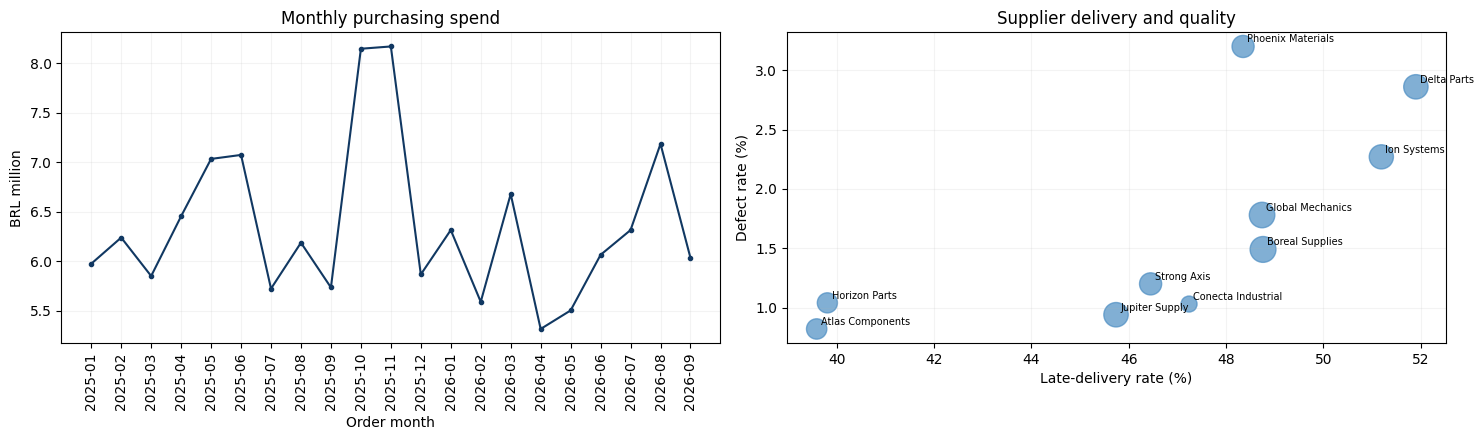

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(q2.ano_mes, q2.gasto_mensal / 1e6, color="#113862", marker="o", markersize=3)
axes[0].set(title="Monthly purchasing spend", xlabel="Order month", ylabel="BRL million")
axes[0].tick_params(axis="x", rotation=90)
axes[1].scatter(q4.taxa_atraso_pct, q4.taxa_defeito_pct, s=q4.gasto_total / 50000, color="#4C8DC2", alpha=.7)
for row in q4.itertuples():
    axes[1].annotate(row.nome_fornecedor, (row.taxa_atraso_pct, row.taxa_defeito_pct), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1].set(title="Supplier delivery and quality", xlabel="Late-delivery rate (%)", ylabel="Defect rate (%)")
for ax in axes: ax.grid(alpha=.15)
fig.tight_layout()
plt.show()

## 15. Reconciliation with the final report

Cross-tool reconciliation covers the full, unfiltered reporting snapshot. The following checks match the stored PBIX tables and displayed headline totals, with report rounding distinguished from exact calculations. Static exports do not validate every interactive filter state.

In [ ]:
expected = {
    "Total spend": (float(compras.valor_total.sum()), 133493473.90, .005),
    "Orders": (int(compras.id_pedido.nunique()), 2500, 0),
    "Units": (int(compras.quantidade.sum()), 636430, 0),
    "Parts": (len(pecas), 100, 0),
    "Suppliers": (len(fornecedores), 10, 0),
    "Quotes": (len(ofertas), 394, 0),
    "Late-delivery rate": (float(compras.dias_atraso.gt(0).mean()), .474, 1e-10),
    "Potential savings": (float(part_analysis.potential_savings.sum()), 36261805.79, .005),
    "Low-coverage parts": (int((part_analysis.suppliers <= 2).sum()), 25, 0),
    "High quote-gap parts": (int((part_analysis.price_gap > .30).sum()), 30, 0),
}
for label, count in [("Q1 - Prioritize", 9), ("Q2 - Negotiate", 21), ("Q3 - Maintain", 46), ("Q4 - Optimize", 24)]:
    expected[label] = (int((part_analysis.quadrant == label).sum()), count, 0)
reconciliation = pd.DataFrame([{"Metric": label, "Calculated": observed, "Expected": target, "Pass": bool(abs(observed-target) <= tolerance)} for label, (observed, target, tolerance) in expected.items()])
display(reconciliation)
if not reconciliation.Pass.all():
    raise ValueError("The approved final reporting snapshot has not been reproduced.")
# Independent SQL/Pandas aggregation agreement.
assert abs(float(q1.gasto_total.iloc[0]) - compras.valor_total.sum()) < .005
print("All 14 report-snapshot checks passed; SQL and Pandas spending totals agree.")

All 14 report-snapshot checks passed; SQL and Pandas spending totals agree.


,Metric,Calculated,Expected,Pass
0,Total spend,"133,493,473.9000","133,493,473.9000",True
1,Orders,"2,500.0000","2,500.0000",True
2,Units,"636,430.0000","636,430.0000",True
3,Parts,100.0000,100.0000,True
4,Suppliers,10.0000,10.0000,True
5,Quotes,394.0000,394.0000,True
6,Late-delivery rate,0.4740,0.4740,True
7,Potential savings,"36,261,805.7900","36,261,805.7900",True
8,Low-coverage parts,25.0000,25.0000,True
9,High quote-gap parts,30.0000,30.0000,True


## 16. Findings and purchasing implications

The final snapshot records R$133.49 million of spend and R$36.26 million in nonnegative quote-based potential savings. Safety leads category opportunities; Industrial Lock 093 leads individual parts. Nine high-spend, high-gap parts form the first negotiation screening segment.

Supplier qualification should balance cost, delivery, defects and coverage. Atlas Components has a favorable delivery/quality profile; that profile is distinct from a weighted composite score. Low coverage flags 25 parts for further supply-risk assessment.

The supplied dashboard's action-impact estimates are fixed fractions of the savings scenario and may overlap. They are not additive or independently demonstrated benefits. No operational savings are claimed from this synthetic academic case.

## 17. Analytical exports

Aggregate outputs preserve the methods and indicators used for inspection. The approved inputs remain separate from the public portfolio; the SQLite database and detailed analytical exports stay in the configured local output directory.

In [ ]:
validation.to_csv(OUTPUT_DIR / "validation.csv", index=False)
reconciliation.to_csv(OUTPUT_DIR / "report_reconciliation.csv", index=False)
part_analysis.reset_index().to_csv(OUTPUT_DIR / "part_analysis.csv", index=False)
ranking.to_csv(OUTPUT_DIR / "supplier_score.csv", index=False)
for name, frame in {"purchasing_overview": q1, "monthly_spend": q2, "category_spend": q3, "supplier_performance": q4}.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
conn.close()
print("Analytical exports completed; SQLite connection closed.")

Analytical exports completed; SQLite connection closed.
